# Exploratory Data Analysis on Retail Sales Data
**Oasis Infobyte SIP — Data Analytics | Level 1 | Task 1**

## Dataset
Kaggle: Customer Shopping Dataset – Retail Sales Data  
Expected file: `retail_sales_dataset.csv`

This notebook is adapted to the dataset columns:
`invoice_no`, `customer_id`, `gender`, `age`, `category`, `quantity`, `price`, `payment_method`, `invoice_date`, `shopping_mall`.

**Important:** This dataset has product categories, not individual product names. Therefore, this notebook analyzes category performance rather than a Top 10 individual-products chart.

## Objective
Inspect and clean the data, study customer demographics and sales trends, analyze category performance, visualize numerical relationships, and develop evidence-based recommendations.


In [27]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

DATA_PATH = Path("retail_sales_dataset.csv")
df = pd.read_csv(DATA_PATH)

# Standardize column names and calculate sales revenue.
df.columns = df.columns.str.strip().str.lower()
required_columns = [
    "invoice_no", "customer_id", "gender", "age", "category",
    "quantity", "price", "payment_method", "invoice_date", "shopping_mall"
]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}. Check the CSV header.")

df["invoice_date"] = pd.to_datetime(df["invoice_date"], dayfirst=True, errors="coerce")
for col in ["age", "quantity", "price"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Revenue per transaction line = quantity × unit price.
df["sales_amount"] = df["quantity"] * df["price"]

df.head()


,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall,sales_amount
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,2022-08-05,Kanyon,7502.00
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,2021-12-12,Forum Istanbul,5401.53
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,2021-11-09,Metrocity,300.08
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,2021-05-16,Metropol AVM,15004.25
4,I337046,C189076,Female,53,Books,4,60.60,Cash,2021-10-24,Kanyon,242.40


## 1. Initial data inspection
Check dimensions, data types, missing values, duplicate rows, and basic data quality.

In [28]:
print("Rows, columns:", df.shape)
display(df.dtypes.to_frame("Data type"))
display(df.isna().sum().to_frame("Missing values"))
print("Duplicate rows:", df.duplicated().sum())
print("Invalid dates:", df["invoice_date"].isna().sum())
display(df[["age", "quantity", "price", "sales_amount"]].describe().round(2))


Rows, columns: (99457, 11)


,Data type
invoice_no,str
customer_id,str
gender,str
age,int64
category,str
quantity,int64
price,float64
payment_method,str
invoice_date,datetime64[us]
shopping_mall,str


,Missing values
invoice_no,0
customer_id,0
gender,0
age,0
category,0
quantity,0
price,0
payment_method,0
invoice_date,0
shopping_mall,0


Duplicate rows: 0
Invalid dates: 0


,age,quantity,price,sales_amount
count,99457.00,99457.00,99457.00,99457.00
mean,43.43,3.00,689.26,2528.79
std,14.99,1.41,941.18,4222.48
min,18.00,1.00,5.23,5.23
25%,30.00,2.00,45.45,136.35
50%,43.00,3.00,203.30,600.17
75%,56.00,4.00,1200.32,2700.72
max,69.00,5.00,5250.00,26250.00


## 2. Data cleaning
Remove exact duplicate rows and rows missing fields required for the analyses. Keep a count of removed rows.

In [29]:
before = len(df)
df = df.drop_duplicates().copy()
required_for_analysis = ["invoice_date", "gender", "age", "category", "quantity", "price", "sales_amount"]
df = df.dropna(subset=required_for_analysis).copy()
df = df[(df["quantity"] > 0) & (df["price"] >= 0) & (df["age"] > 0)].copy()
print("Rows before cleaning:", before)
print("Rows after cleaning:", len(df))
print("Rows removed:", before - len(df))


Rows before cleaning: 99457
Rows after cleaning: 99457
Rows removed: 0


## 3. Descriptive statistics
Calculate mean, median, mode, and standard deviation for numeric analysis columns.

In [30]:
numeric_cols = ["age", "quantity", "price", "sales_amount"]
summary = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Mode": df[numeric_cols].mode().iloc[0],
    "Standard Deviation": df[numeric_cols].std()
})
display(summary.round(2))


,Mean,Median,Mode,Standard Deviation
age,43.43,43.00,37.00,14.99
quantity,3.00,3.00,3.00,1.41
price,689.26,203.30,600.16,941.18
sales_amount,2528.79,600.17,1200.32,4222.48


## 4. Monthly and quarterly sales trends
Revenue is calculated as `quantity × price` and grouped by invoice date.

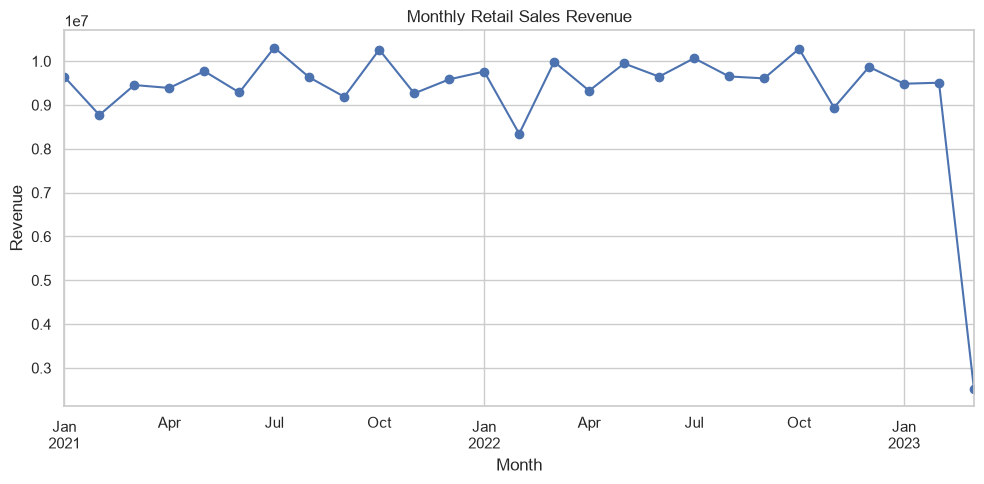

Highest-revenue month: July 2021
Revenue in highest month: 10311119.68


In [31]:
monthly_sales = df.set_index("invoice_date")["sales_amount"].resample("MS").sum()
fig, ax = plt.subplots()
monthly_sales.plot(ax=ax, marker="o")
ax.set(title="Monthly Retail Sales Revenue", xlabel="Month", ylabel="Revenue")
plt.tight_layout()
plt.show()
print("Highest-revenue month:", monthly_sales.idxmax().strftime("%B %Y"))
print("Revenue in highest month:", round(monthly_sales.max(), 2))


**Observation — Monthly trend:** After running this chart, write which month has the highest and lowest revenue and whether revenue rises, falls, or fluctuates across the period. Use the values printed above.

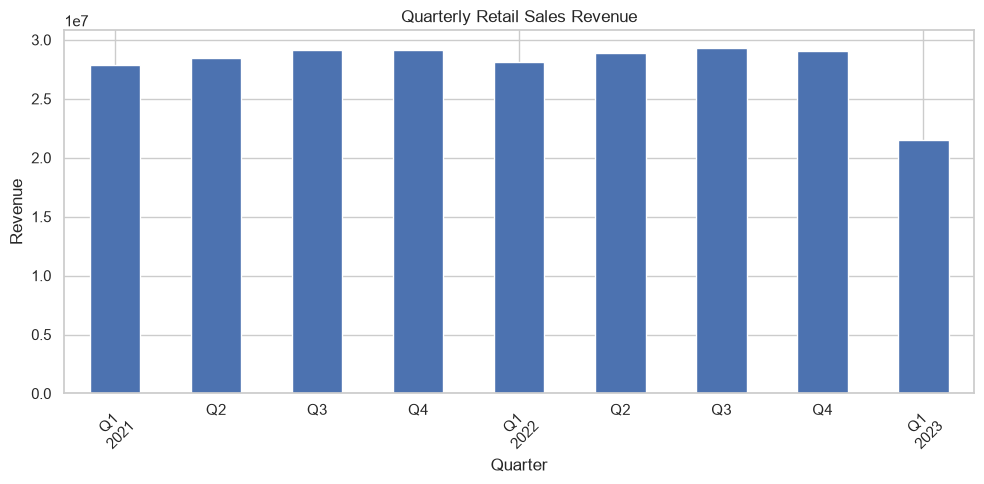

Highest-revenue quarter: 2022Q3
Revenue in highest quarter: 29326937.83


In [32]:
quarterly_sales = df.set_index("invoice_date")["sales_amount"].resample("QS").sum()
fig, ax = plt.subplots()
quarterly_sales.plot(kind="bar", ax=ax)
ax.set(title="Quarterly Retail Sales Revenue", xlabel="Quarter", ylabel="Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print("Highest-revenue quarter:", quarterly_sales.idxmax().to_period("Q"))
print("Revenue in highest quarter:", round(quarterly_sales.max(), 2))


**Observation — Quarterly trend:** Record the strongest and weakest quarters and describe any seasonal pattern visible in the chart.

## 5. Customer demographics
Analyze transaction counts by age group and gender. These are transaction records, not necessarily unique-customer counts.

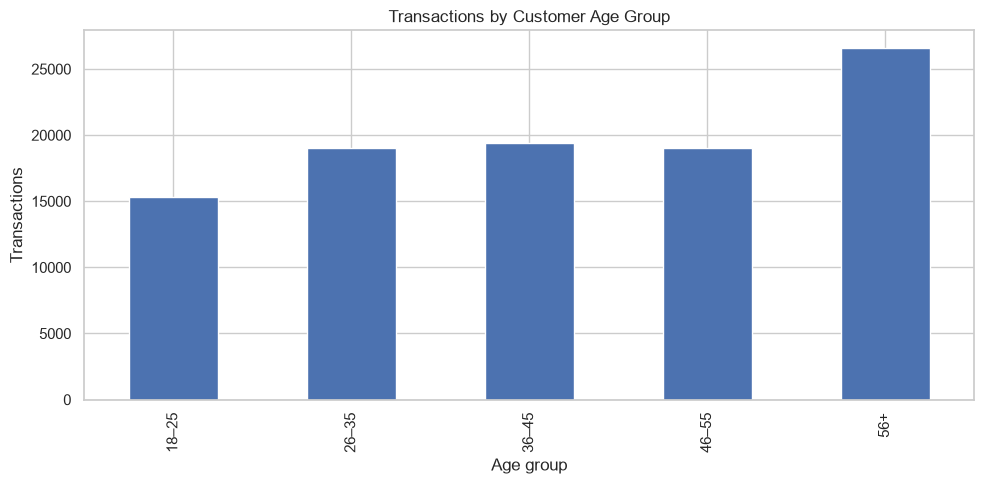

Largest age group: 56+ | transactions: 26587


In [33]:
age_bins = [0, 25, 35, 45, 55, 120]
age_labels = ["18–25", "26–35", "36–45", "46–55", "56+"]
df["age_group"] = pd.cut(df["age"], bins=age_bins, labels=age_labels, include_lowest=True)
age_counts = df["age_group"].value_counts().sort_index()
fig, ax = plt.subplots()
age_counts.plot(kind="bar", ax=ax)
ax.set(title="Transactions by Customer Age Group", xlabel="Age group", ylabel="Transactions")
plt.tight_layout()
plt.show()
print("Largest age group:", age_counts.idxmax(), "| transactions:", age_counts.max())


**Observation — Age groups:** Identify the age group with the most transactions and compare it with the smallest group.

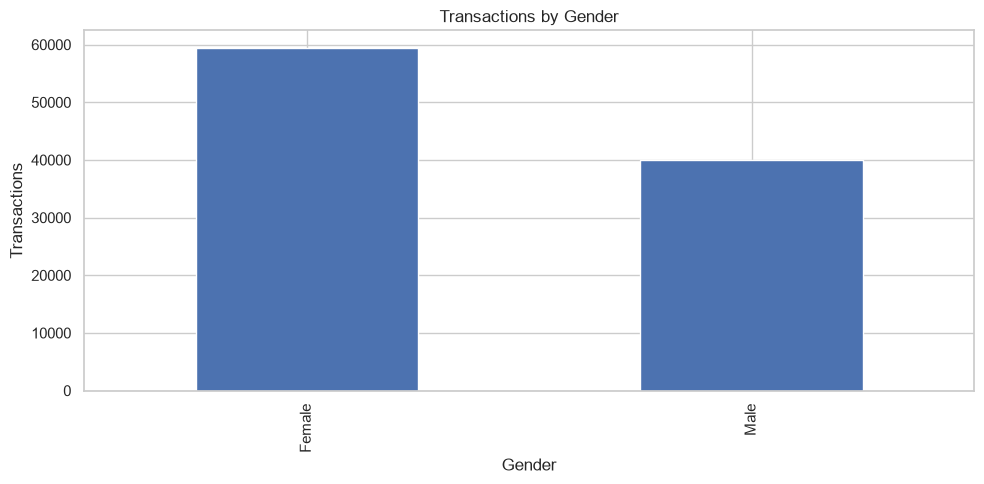

,Transactions
gender,
Female,59482
Male,39975


Gender with most transactions: Female


In [34]:
gender_counts = df["gender"].value_counts()
fig, ax = plt.subplots()
gender_counts.plot(kind="bar", ax=ax)
ax.set(title="Transactions by Gender", xlabel="Gender", ylabel="Transactions")
plt.tight_layout()
plt.show()
display(gender_counts.to_frame("Transactions"))
print("Gender with most transactions:", gender_counts.idxmax())


**Observation — Gender:** State which gender has more transactions and whether the difference appears large or small.

## 6. Product category performance
The dataset has `category` but no individual product-name field. Analyze revenue and units by category instead.

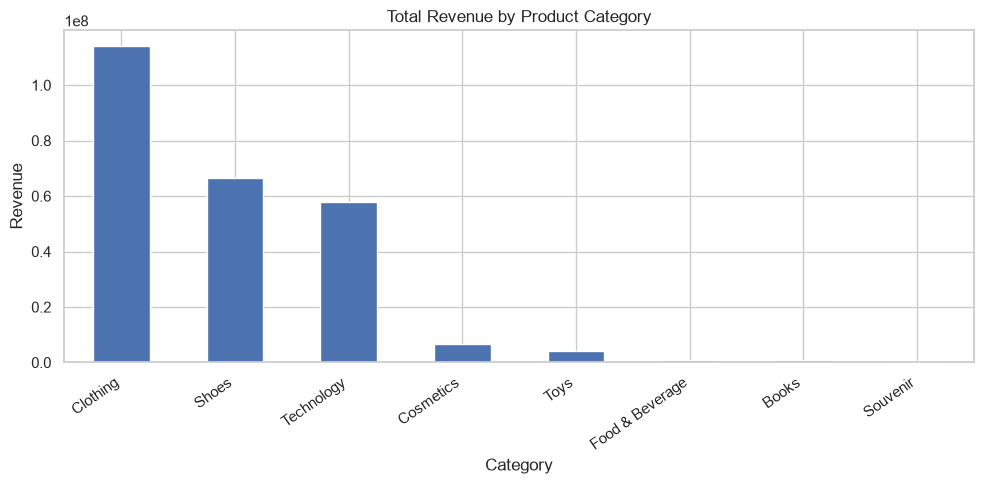

,Revenue
category,
Clothing,1.139968e+08
Shoes,6.655345e+07
Technology,5.786235e+07
Cosmetics,6.792863e+06
Toys,3.980426e+06
Food & Beverage,8.495351e+05
Books,8.345529e+05
Souvenir,6.358247e+05


Highest-revenue category: Clothing


In [35]:
category_revenue = df.groupby("category")["sales_amount"].sum().sort_values(ascending=False)
fig, ax = plt.subplots()
category_revenue.plot(kind="bar", ax=ax)
ax.set(title="Total Revenue by Product Category", xlabel="Category", ylabel="Revenue")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()
display(category_revenue.to_frame("Revenue").round(2))
print("Highest-revenue category:", category_revenue.idxmax())


**Observation — Category revenue:** Identify the highest- and lowest-revenue categories. Mention their revenue values from the table.

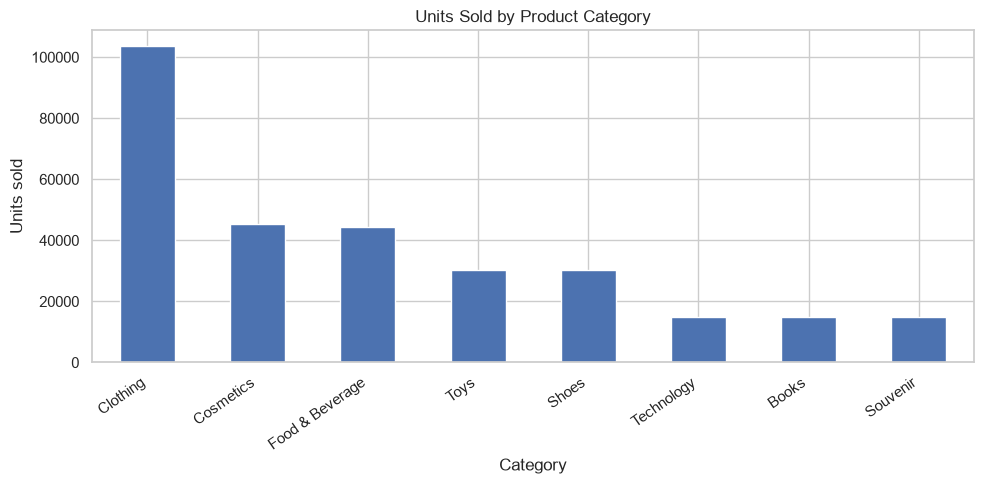

,Units sold
category,
Clothing,103558
Cosmetics,45465
Food & Beverage,44277
Toys,30321
Shoes,30217
Technology,15021
Books,14982
Souvenir,14871


Most units sold category: Clothing


In [36]:
category_units = df.groupby("category")["quantity"].sum().sort_values(ascending=False)
fig, ax = plt.subplots()
category_units.plot(kind="bar", ax=ax)
ax.set(title="Units Sold by Product Category", xlabel="Category", ylabel="Units sold")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()
display(category_units.to_frame("Units sold"))
print("Most units sold category:", category_units.idxmax())


**Observation — Category units:** Compare the category with the most units sold against the category with the highest revenue. They may differ.

## 7. Correlation heatmap
Correlation shows linear association, not causation.

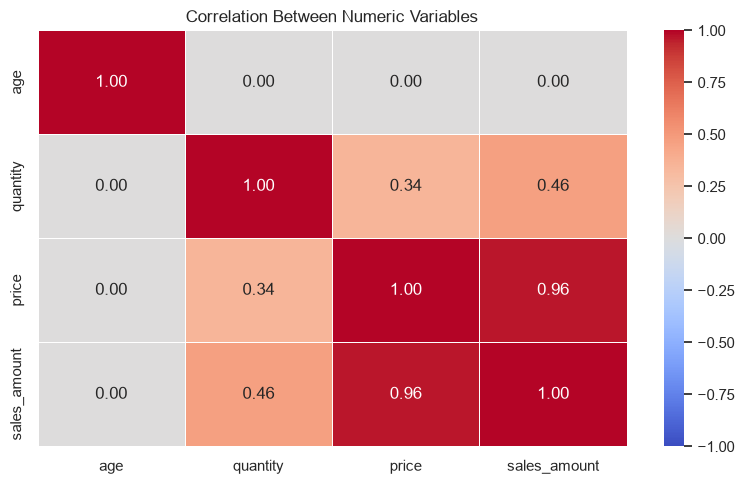

,age,quantity,price,sales_amount
age,1.0,0.00,0.00,0.00
quantity,0.0,1.00,0.34,0.46
price,0.0,0.34,1.00,0.96
sales_amount,0.0,0.46,0.96,1.00


In [37]:
corr_cols = ["age", "quantity", "price", "sales_amount"]
corr = df[corr_cols].corr()
plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, vmin=-1, vmax=1)
plt.title("Correlation Between Numeric Variables")
plt.tight_layout()
plt.show()
display(corr.round(2))


**Observation — Correlation:** Report the strongest positive and negative relationships. Note that sales amount is calculated from quantity multiplied by price, so its relationship with those variables is expected.

## 8. Additional insight: sales by shopping mall
Compare total sales across shopping malls to identify locations contributing most to revenue.

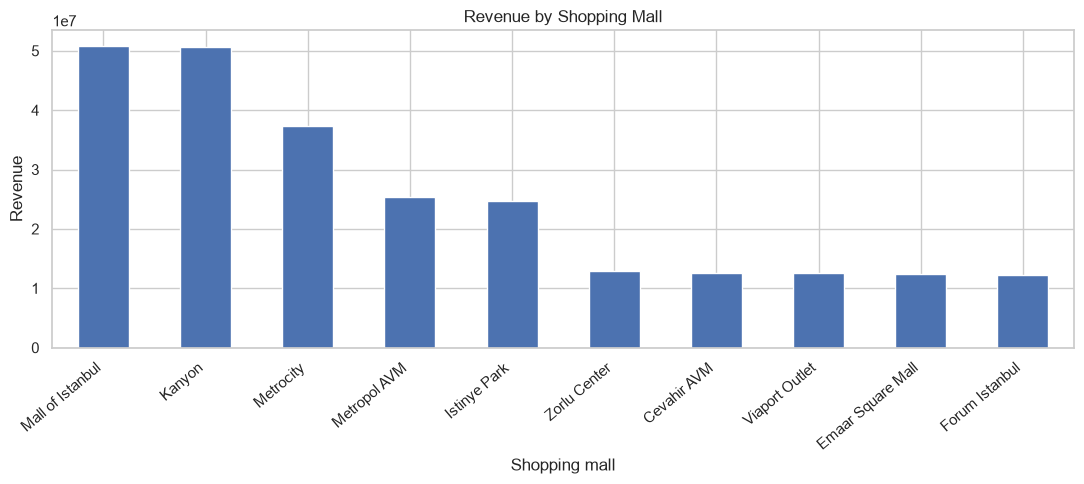

,Revenue
shopping_mall,
Mall of Istanbul,50872481.68
Kanyon,50554231.10
Metrocity,37302787.33
Metropol AVM,25379913.19
Istinye Park,24618827.68
Zorlu Center,12901053.82
Cevahir AVM,12645138.20
Viaport Outlet,12521339.72
Emaar Square Mall,12406100.29


Highest-revenue mall: Mall of Istanbul


In [38]:
mall_revenue = df.groupby("shopping_mall")["sales_amount"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 5))
mall_revenue.plot(kind="bar", ax=ax)
ax.set(title="Revenue by Shopping Mall", xlabel="Shopping mall", ylabel="Revenue")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()
display(mall_revenue.to_frame("Revenue").round(2))
print("Highest-revenue mall:", mall_revenue.idxmax())


**Observation — Shopping mall:** Identify the top and bottom malls by revenue. Consider whether the difference may be related to transaction volume or average transaction value.

## 9. Evidence-based business recommendations
The following cell generates findings from the actual dataset. Review the outputs and write at least three recommendations in your own words.

In [39]:
top_category = category_revenue.idxmax()
low_category = category_revenue.idxmin()
top_mall = mall_revenue.idxmax()
top_age = age_counts.idxmax()
top_gender = gender_counts.idxmax()
top_month = monthly_sales.idxmax().strftime("%B %Y")

print(f"1. Inventory planning: Review stock allocation for {top_category}, the category with the highest recorded revenue.")
print(f"2. Category improvement: Investigate pricing, assortment, and promotion opportunities for {low_category}, the lowest-revenue category.")
print(f"3. Location planning: Study practices at {top_mall}, the highest-revenue mall, before deciding whether similar approaches can be used elsewhere.")
print(f"4. Customer campaigns: Test age-appropriate campaigns for the {top_age} transaction segment; measure results before scaling.")
print(f"5. Timing: Review staffing and promotional plans around {top_month}, the highest-revenue month.")


1. Inventory planning: Review stock allocation for Clothing, the category with the highest recorded revenue.
2. Category improvement: Investigate pricing, assortment, and promotion opportunities for Souvenir, the lowest-revenue category.
3. Location planning: Study practices at Mall of Istanbul, the highest-revenue mall, before deciding whether similar approaches can be used elsewhere.
4. Customer campaigns: Test age-appropriate campaigns for the 56+ transaction segment; measure results before scaling.
5. Timing: Review staffing and promotional plans around July 2021, the highest-revenue month.


## 10. Conclusion

- This project analyzed the Customer Shopping Dataset
using Python, Pandas, Matplotlib, and Seaborn.

- The analysis identified Clothing as the highest-revenue
category and Souvenir as the lowest-revenue category.
Mall of Istanbul generated the highest revenue.
The 56+ age group recorded the highest number of
transactions, and July 2021 was the highest-revenue month.

- Based on these findings, the business should improve
inventory planning, investigate low-performing categories,
study successful shopping mall performance, and develop
targeted customer promotions.

- This analysis provides useful insights for improving
retail sales and business decision-making.
## 11. Submission checklist
- [ ] Use the real Kaggle CSV, not the synthetic starter CSV.
- [ ] Confirm the source link and dataset attribution in the README.
- [ ] Run every cell from top to bottom.
- [ ] Add evidence-based observations after every chart.
- [ ] Include at least three actionable recommendations.
- [ ] Save the notebook with outputs and add screenshots.
- [ ] Commit the project using the required `OIBSIP/DataAnalytics-L1-EDARetailSales/` structure.
